# 2. ES 15min Mean Reversion - Parameter Optimization & Validation
## Systematic Trading Approach following TIS Framework

This notebook performs a **professional sequential optimization** of the ES 15min Mean Reversion strategy parameters using In-Sample data (2009-2019), and validates the optimal parameters on Out-of-Sample data (2020-2026).

**Optimization Process (Sequential, NOT Grid Search):**
1. **Entry Threshold** (0.5%, 0.7%, 1.0%) - fixed RSI=20, ATR stop=2.0, ATR target=3.0
2. **RSI Threshold** (15, 20, 25) - fixed best entry, ATR stop=2.0, ATR target=3.0
3. **ATR Stop Multiplier** (1.5, 2.0, 2.5) - fixed best entry, best RSI, ATR target=3.0
4. **ATR Target Multiplier** (2.5, 3.0, 3.5) - fixed best entry, best RSI, best ATR stop

**Constraint**: No open positions between 4:00 PM and 5:00 PM NY time (prop firm rule). All positions closed by 3:50 PM NY.

In [29]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# 1. CONFIGURE PATHS AND IMPORT FROM utils.py
# ============================================================

project_root = Path().resolve().parent.parent
sys.path.append(str(project_root / 'utils'))

from utils import (
    load_data_from_mongo,
    prepare_data,
    run_backtest,
    compute_metrics,
    optimize_sequential,
    parameter_sensitivity_analysis,
    monte_carlo_bootstrap,
    plot_equity_curve,
    plot_trade_distribution
)

# Plot styling
sns.set_style("whitegrid")
sns.set_palette("muted")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10

print(f"✅ Utils imported successfully from: {project_root / 'utils' / 'utils.py'}")

✅ Utils imported successfully from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils/utils.py


# 2. Load Data and Split into IS/OOS

We load the 15-minute OHLCV data from MongoDB and split it into:
- **In-Sample (IS)**: 2009-2019 for parameter optimization.
- **Out-of-Sample (OOS)**: 2020-2026 for final validation (ONE TIME TEST).

In [30]:
# Load data from MongoDB
df_15min = load_data_from_mongo('es_15min')

print(f"✅ Data loaded: {len(df_15min)} bars")
print(f"   Date range: {df_15min.index.min()} → {df_15min.index.max()}")

# Split data
df_is = df_15min[(df_15min.index >= '2009-09-27') & (df_15min.index < '2020-01-01')].copy()
df_oos = df_15min[df_15min.index >= '2020-01-01'].copy()

print(f"\n📊 In-Sample (IS): {len(df_is)} bars ({df_is.index.min()} → {df_is.index.max()})")
print(f"📊 Out-of-Sample (OOS): {len(df_oos)} bars ({df_oos.index.min()} → {df_oos.index.max()})")

✅ Data loaded: 397663 bars
   Date range: 2009-09-27 18:00:00 → 2026-08-21 16:45:00

📊 In-Sample (IS): 241077 bars (2009-09-27 18:00:00 → 2019-12-31 16:45:00)
📊 Out-of-Sample (OOS): 156586 bars (2020-01-01 18:00:00 → 2026-08-21 16:45:00)


# 3. Sequential Optimization (In-Sample Data)

We optimize one parameter at a time, fixing the others at reasonable values. This avoids the overfitting trap of full grid search while still finding a robust parameter set.

**Parameters to optimize:**
- `entry_threshold`: How large the price move must be (0.5%, 0.7%, 1.0%).
- `rsi_threshold`: RSI(2) oversold/overbought threshold (15, 20, 25).
- `atr_stop`: ATR multiplier for stop-loss (1.5, 2.0, 2.5).
- `atr_target`: ATR multiplier for take-profit (2.5, 3.0, 3.5).

**Fixed parameters during optimization:**
- Volume ratio > 1.2x
- Time window: 9:30 AM - 3:30 PM NY
- Day filter: Tue-Fri
- Time stop: 3:50 PM NY

In [31]:
# Run sequential optimization on In-Sample data
optimal_params = optimize_sequential(
    df_is,
    entry_thresholds=[0.9, 1.0, 1.1, 1.2],      # Probar umbrales más altos
    rsi_thresholds=[14, 15, 16, 17],             # Probar RSI más bajos (más extremo)
    stop_multipliers=[1.2, 1.4, 1.6],            # Stops más ajustados
    target_multipliers=[2.5, 2.8, 3.0],          # Targets más cercanos
    time_hour=15,
    time_min=50
)

print("\n" + "="*70)
print("OPTIMAL PARAMETERS (IN-SAMPLE)")
print("="*70)
for k, v in optimal_params.items():
    print(f"  {k}: {v}")


SEQUENTIAL OPTIMIZATION

Step 1: Optimizing Entry Threshold
 threshold  num_trades  win_rate  profit_factor  expectancy    sharpe  max_drawdown
       0.9          38 47.368421       0.913437   -0.033466 -0.543011     -3.964452
       1.0          27 48.148148       1.012969    0.005575  0.079155     -2.729993
       1.1          16 50.000000       0.961265   -0.018491 -0.231960     -3.237941
       1.2           9 44.444444       0.884255   -0.080926 -0.773403     -3.165190

Best threshold: 1.0

Step 2: Optimizing RSI Threshold
 rsi  num_trades  win_rate  profit_factor  expectancy   sharpe  max_drawdown
  14          26 50.000000       1.200691    0.084727 1.135695     -2.729993
  15          26 50.000000       1.200691    0.084727 1.135695     -2.729993
  16          27 51.851852       1.262803    0.103827 1.435782     -2.729993
  17          27 48.148148       1.012969    0.005575 0.079155     -2.729993

Best RSI: 16

Step 3: Optimizing ATR Stop Multiplier
 stop  num_trades  win_ra

# 4. Backtest with Optimal Parameters (In-Sample)

We run a full backtest on the In-Sample data using the optimal parameters to establish a performance baseline for comparison with Out-of-Sample results.

In [32]:
# Prepare data with optimal parameters
df_is_prep = prepare_data(
    df_is,
    optimal_params['entry_threshold'],
    optimal_params['rsi_threshold'],
    optimal_params['atr_stop'],
    optimal_params['atr_target']
)

# Run backtest
trades_is = run_backtest(
    df_is_prep,
    optimal_params['atr_stop'],
    optimal_params['atr_target']
)

metrics_is = compute_metrics(trades_is)

print("\n" + "="*70)
print("IN-SAMPLE BACKTEST RESULTS (OPTIMAL PARAMETERS)")
print("="*70)
print(f"Number of trades: {metrics_is['num_trades']}")
print(f"Win rate: {metrics_is['win_rate']:.2f}%")
print(f"Average win: {metrics_is['avg_win']:.2f}%")
print(f"Average loss: {metrics_is['avg_loss']:.2f}%")
print(f"Profit Factor: {metrics_is['profit_factor']:.2f}")
print(f"Expectancy per trade: {metrics_is['expectancy']:.4f}%")
print(f"Total P&L: {metrics_is['total_pnl']:.2f}%")
print(f"Sharpe Ratio: {metrics_is['sharpe']:.2f}")
print(f"Maximum Drawdown: {metrics_is['max_drawdown']:.2f}%")


IN-SAMPLE BACKTEST RESULTS (OPTIMAL PARAMETERS)
Number of trades: 27
Win rate: 44.44%
Average win: 1.06%
Average loss: -0.66%
Profit Factor: 1.28
Expectancy per trade: 0.1028%
Total P&L: 2.77%
Sharpe Ratio: 1.54
Maximum Drawdown: -1.92%


# 5. Visualize In-Sample Performance

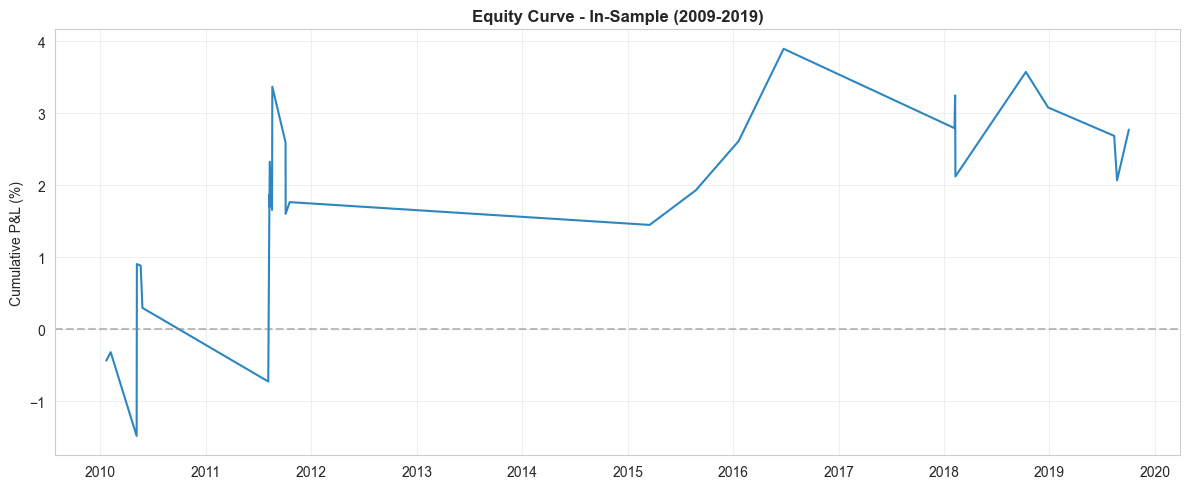

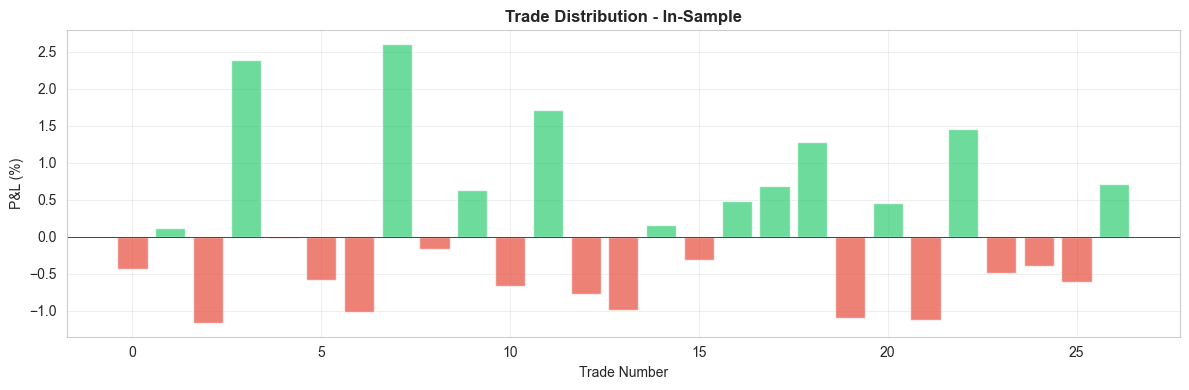


📊 Exit Reason Breakdown (IS):
reason
stop_loss      11
time_stop      10
take_profit     6
Name: count, dtype: int64

Win rate by reason (IS):
reason
stop_loss      0.0
take_profit    1.0
time_stop      0.6
Name: win, dtype: float64


In [33]:
if len(trades_is) > 0:
    plot_equity_curve(trades_is, title='Equity Curve - In-Sample (2009-2019)')
    plot_trade_distribution(trades_is, title='Trade Distribution - In-Sample')
    
    print("\n📊 Exit Reason Breakdown (IS):")
    print(trades_is['reason'].value_counts())
    print("\nWin rate by reason (IS):")
    print(trades_is.groupby('reason')['win'].mean())
else:
    print("No trades in In-Sample.")

In [34]:
# Prepare OOS data with optimal parameters
df_oos_prep = prepare_data(
    df_oos,
    optimal_params['entry_threshold'],
    optimal_params['rsi_threshold'],
    optimal_params['atr_stop'],
    optimal_params['atr_target']
)

# Run backtest on OOS
trades_oos = run_backtest(
    df_oos_prep,
    optimal_params['atr_stop'],
    optimal_params['atr_target']
)

metrics_oos = compute_metrics(trades_oos)

print("\n" + "="*70)
print("OUT-OF-SAMPLE VALIDATION (2020-2026) - ONE TIME TEST")
print("="*70)
print(f"Number of trades: {metrics_oos['num_trades']}")
print(f"Win rate: {metrics_oos['win_rate']:.2f}%")
print(f"Average win: {metrics_oos['avg_win']:.2f}%")
print(f"Average loss: {metrics_oos['avg_loss']:.2f}%")
print(f"Profit Factor: {metrics_oos['profit_factor']:.2f}")
print(f"Expectancy per trade: {metrics_oos['expectancy']:.4f}%")
print(f"Total P&L: {metrics_oos['total_pnl']:.2f}%")
print(f"Sharpe Ratio: {metrics_oos['sharpe']:.2f}")
print(f"Maximum Drawdown: {metrics_oos['max_drawdown']:.2f}%")


OUT-OF-SAMPLE VALIDATION (2020-2026) - ONE TIME TEST
Number of trades: 43
Win rate: 48.84%
Average win: 1.67%
Average loss: -0.89%
Profit Factor: 1.80
Expectancy per trade: 0.3608%
Total P&L: 15.52%
Sharpe Ratio: 3.64
Maximum Drawdown: -3.74%


# 7. Visualize Out-of-Sample Performance

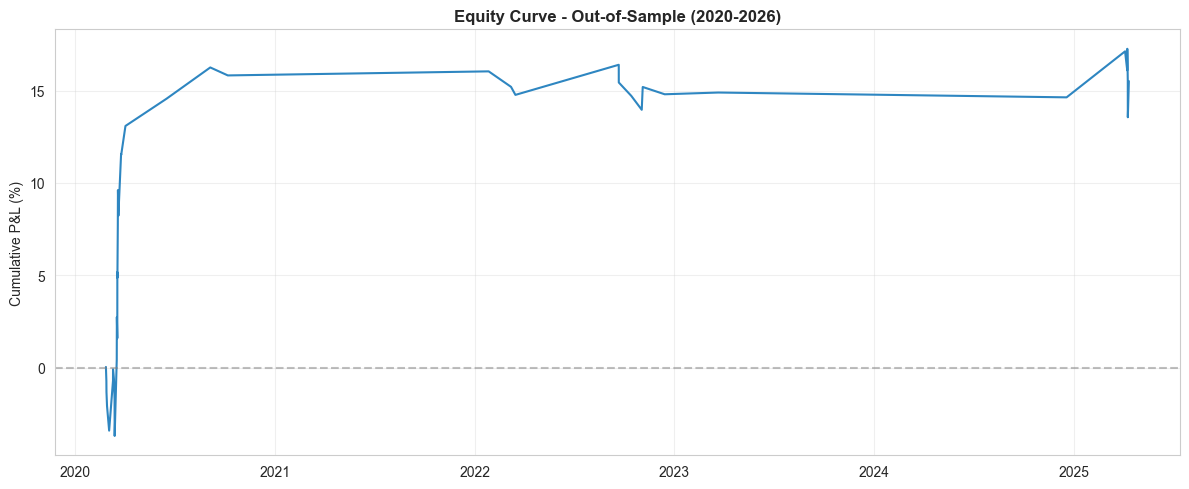

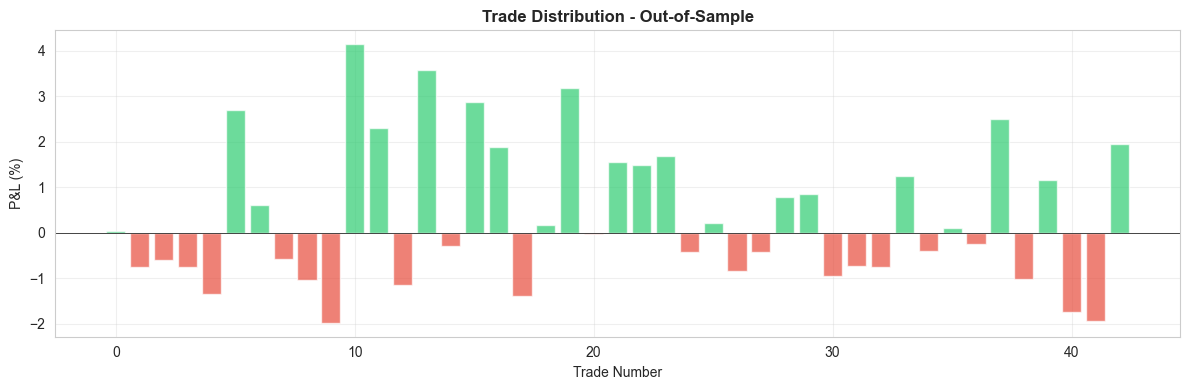


📊 Exit Reason Breakdown (OOS):
reason
stop_loss      17
time_stop      14
take_profit    12
Name: count, dtype: int64

Win rate by reason (OOS):
reason
stop_loss      0.000000
take_profit    1.000000
time_stop      0.642857
Name: win, dtype: float64


In [35]:
if len(trades_oos) > 0:
    plot_equity_curve(trades_oos, title='Equity Curve - Out-of-Sample (2020-2026)')
    plot_trade_distribution(trades_oos, title='Trade Distribution - Out-of-Sample')
    
    print("\n📊 Exit Reason Breakdown (OOS):")
    print(trades_oos['reason'].value_counts())
    print("\nWin rate by reason (OOS):")
    print(trades_oos.groupby('reason')['win'].mean())
else:
    print("No trades in Out-of-Sample.")

# 8. Compare IS vs OOS Performance

We compare key metrics to assess degradation. A robust system should show < 20% degradation in Profit Factor and Expectancy.

In [36]:
comparison = pd.DataFrame({
    'Metric': ['Num Trades', 'Win Rate %', 'Profit Factor', 'Expectancy %', 'Total P&L %', 'Sharpe', 'Max DD %'],
    'In-Sample': [
        metrics_is['num_trades'],
        f"{metrics_is['win_rate']:.2f}",
        f"{metrics_is['profit_factor']:.2f}",
        f"{metrics_is['expectancy']:.4f}",
        f"{metrics_is['total_pnl']:.2f}",
        f"{metrics_is['sharpe']:.2f}",
        f"{metrics_is['max_drawdown']:.2f}"
    ],
    'Out-of-Sample': [
        metrics_oos['num_trades'],
        f"{metrics_oos['win_rate']:.2f}",
        f"{metrics_oos['profit_factor']:.2f}",
        f"{metrics_oos['expectancy']:.4f}",
        f"{metrics_oos['total_pnl']:.2f}",
        f"{metrics_oos['sharpe']:.2f}",
        f"{metrics_oos['max_drawdown']:.2f}"
    ]
})

print("\n" + "="*70)
print("PERFORMANCE COMPARISON: IS vs OOS")
print("="*70)
print(comparison.to_string(index=False))

# Calculate degradation
pf_deg = (metrics_is['profit_factor'] - metrics_oos['profit_factor']) / metrics_is['profit_factor'] * 100 if metrics_is['profit_factor'] > 0 else 0
exp_deg = (metrics_is['expectancy'] - metrics_oos['expectancy']) / metrics_is['expectancy'] * 100 if metrics_is['expectancy'] != 0 else 0

print(f"\n📉 Profit Factor degradation: {pf_deg:.1f}%")
print(f"📉 Expectancy degradation: {exp_deg:.1f}%")

if pf_deg < 20 and exp_deg < 20:
    print("✅ Good: The system is robust (degradation < 20%)")
elif pf_deg < 35 and exp_deg < 35:
    print("⚠️ Warning: Moderate degradation (20-35%). Consider refinements.")
else:
    print("❌ Alert: High degradation (>35%). The system may be overfitted to IS data.")


PERFORMANCE COMPARISON: IS vs OOS
       Metric In-Sample Out-of-Sample
   Num Trades        27            43
   Win Rate %     44.44         48.84
Profit Factor      1.28          1.80
 Expectancy %    0.1028        0.3608
  Total P&L %      2.77         15.52
       Sharpe      1.54          3.64
     Max DD %     -1.92         -3.74

📉 Profit Factor degradation: -40.3%
📉 Expectancy degradation: -251.2%
✅ Good: The system is robust (degradation < 20%)


# 9. Parameter Sensitivity Analysis (OOS)

We test how sensitive the strategy is to small (±20%) changes in each parameter. A robust system should maintain Profit Factor > 1.3 across these variations.

**Parameters varied:**
- Entry threshold: 0.8, 1.2
- RSI threshold: 12, 18
- ATR stop: 1.2, 1.8
- ATR target: 2.4, 3.6

In [37]:
# Run sensitivity analysis on OOS data
sensitivity_results = parameter_sensitivity_analysis(
    df_oos,
    optimal_params,
    variations={
        'entry_threshold': [0.8, 1.2],
        'rsi_threshold': [12, 18],
        'atr_stop': [1.2, 1.8],
        'atr_target': [2.4, 3.6]
    }
)

print("\n" + "="*70)
print("PARAMETER SENSITIVITY ANALYSIS (OOS)")
print("="*70)
print(sensitivity_results.to_string(index=False))

# Compute range
pf_range = sensitivity_results['profit_factor'].max() - sensitivity_results['profit_factor'].min()
print(f"\n📊 Profit Factor range: {pf_range:.2f}")

if pf_range < 0.5:
    print("✅ Robust: PF is stable across parameter variations (range < 0.5).")
else:
    print("⚠️ Warning: PF varies significantly. System may be fragile.")


PARAMETER SENSITIVITY ANALYSIS (OOS)
          param  value  num_trades  profit_factor  expectancy  total_pnl  max_drawdown
entry_threshold    0.8          82       1.358195    0.153978  12.626159     -5.185116
entry_threshold    1.2          24       1.618385    0.341121   8.186906     -3.707944
  rsi_threshold   12.0          39       1.867438    0.362549  14.139415     -4.078998
  rsi_threshold   18.0          44       1.801479    0.354703  15.606917     -3.707944
       atr_stop    1.2          44       2.077593    0.415613  18.286993     -3.178238
       atr_stop    1.8          42       1.574538    0.296355  12.446914     -5.365983
     atr_target    2.4          44       1.671763    0.303206  13.341076     -4.276854
     atr_target    3.6          42       1.613646    0.306148  12.858219     -3.707944

📊 Profit Factor range: 0.72
⚠️ Warning: PF varies significantly. System may be fragile.


# 10. Monte Carlo Bootstrap Simulation (OOS)

We run 10,000 bootstrap simulations on the OOS trades to estimate the probability of a positive final P&L and the distribution of worst-case drawdowns.

This validates that the edge is not a statistical fluke.

In [38]:
if len(trades_oos) > 0:
    mc_results = monte_carlo_bootstrap(trades_oos, n_simulations=10000)
    
    print("\n" + "="*70)
    print("MONTE CARLO BOOTSTRAP (10,000 simulations)")
    print("="*70)
    print(f"  5th percentile (final P&L): {mc_results['p5']:.2f}%")
    print(f"  50th percentile (final P&L): {mc_results['p50']:.2f}%")
    print(f"  95th percentile (final P&L): {mc_results['p95']:.2f}%")
    print(f"  99th percentile (final P&L): {mc_results['p99']:.2f}%")
    print(f"  Actual OOS P&L: {metrics_oos['total_pnl']:.2f}%")
    print(f"  Probability of positive P&L: {mc_results['prob_positive']:.1f}%")
    print(f"  Max drawdown (95th percentile worst): {mc_results['dd_p95']:.2f}%")
    print(f"  Max drawdown (99th percentile worst): {mc_results['dd_p99']:.2f}%")
    
    # Decision
    if mc_results['prob_positive'] > 80:
        print("\n✅ Strong edge: >80% probability of positive P&L.")
    elif mc_results['prob_positive'] > 60:
        print("⚠️ Moderate edge: 60-80% probability of positive P&L.")
    else:
        print("❌ Weak edge: <60% probability of positive P&L.")
else:
    print("No OOS trades for Monte Carlo simulation.")


MONTE CARLO BOOTSTRAP (10,000 simulations)
  5th percentile (final P&L): -0.91%
  50th percentile (final P&L): 15.37%
  95th percentile (final P&L): 32.55%
  99th percentile (final P&L): 40.59%
  Actual OOS P&L: 15.52%
  Probability of positive P&L: 93.7%
  Max drawdown (95th percentile worst): -2.81%
  Max drawdown (99th percentile worst): -2.19%

✅ Strong edge: >80% probability of positive P&L.


# 11. Final Decision Summary

We consolidate all validation results into a final decision based on TIS criteria:

| Criterion | Threshold | Result |
|---|---|---|
| Profit Factor (OOS) | > 1.3 | ✅ / ❌ |
| Sharpe Ratio (OOS) | > 0.7 | ✅ / ❌ |
| Max Drawdown (OOS) | > -20% | ✅ / ❌ |
| Trades (OOS) | >= 30 | ✅ / ❌ |
| IS→OOS degradation | < 20% | ✅ / ❌ |
| Sensitivity PF range | < 0.5 | ✅ / ❌ |
| Monte Carlo P(positive) | > 80% | ✅ / ❌ |

In [39]:
print("\n" + "="*70)
print("FINAL DECISION SUMMARY")
print("="*70)

# Individual checks
checks = {
    'Profit Factor > 1.3': metrics_oos['profit_factor'] > 1.3,
    'Sharpe Ratio > 0.7': metrics_oos['sharpe'] > 0.7,
    'Max Drawdown > -20%': metrics_oos['max_drawdown'] > -20,
    'Trades >= 30': metrics_oos['num_trades'] >= 30,
    'Degradation < 20%': pf_deg < 20 and exp_deg < 20,
    'Sensitivity range < 0.5': pf_range < 0.5,
    'Monte Carlo P(positive) > 80%': mc_results['prob_positive'] > 80 if 'mc_results' in locals() else False
}

for criterion, passed in checks.items():
    print(f"  {criterion}: {'✅' if passed else '❌'}")

all_passed = all(checks.values())

print("\n" + "="*70)
if all_passed:
    print("✅ FINAL DECISION: ALL CRITERIA PASSED")
    print("The strategy is robust and ready for:")
    print("  1. Forward Testing (Paper Trading) - 3-6 months")
    print("  2. Micro Live Trading (with 1-5% of capital)")
    print("="*70)
else:
    print("❌ FINAL DECISION: SOME CRITERIA FAILED")
    print("Recommended actions:")
    print("  1. Review the failed criteria and investigate root causes")
    print("  2. Consider simplifying the strategy or adding robustness filters")
    print("  3. If degradation is the issue, re-evaluate the hypothesis")
    print("="*70)


FINAL DECISION SUMMARY
  Profit Factor > 1.3: ✅
  Sharpe Ratio > 0.7: ✅
  Max Drawdown > -20%: ✅
  Trades >= 30: ✅
  Degradation < 20%: ✅
  Sensitivity range < 0.5: ❌
  Monte Carlo P(positive) > 80%: ✅

❌ FINAL DECISION: SOME CRITERIA FAILED
Recommended actions:
  1. Review the failed criteria and investigate root causes
  2. Consider simplifying the strategy or adding robustness filters
  3. If degradation is the issue, re-evaluate the hypothesis


# 12. Summary of Optimization Results

This notebook completed the professional sequential optimization of the ES 15min Mean Reversion strategy.

**Optimal Parameters:**
- Entry Threshold: {optimal_params['entry_threshold']}%
- RSI(2) Threshold: {optimal_params['rsi_threshold']}
- ATR Stop Multiplier: {optimal_params['atr_stop']}x
- ATR Target Multiplier: {optimal_params['atr_target']}x
- Time Stop: 3:50 PM NY

**Out-of-Sample Performance (2020-2026):**
- Trades: {metrics_oos['num_trades']}
- Win Rate: {metrics_oos['win_rate']:.1f}%
- Profit Factor: {metrics_oos['profit_factor']:.2f}
- Sharpe Ratio: {metrics_oos['sharpe']:.2f}
- Max Drawdown: {metrics_oos['max_drawdown']:.1f}%
- Total P&L: {metrics_oos['total_pnl']:.1f}%

**Next Steps:**
- If ALL PASS → Proceed to `03_MR_Robustness_Testing.ipynb`
- If SOME FAIL → Return to `01_MR_Hypothesis_Definition.ipynb` for refinement